# Import data

In [38]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import lightgbm as lgb

import sys
sys.path.append("..")

from src.data import load_data, split_by_date
from src.metrics import metrics
from src.features import get_holiday_dates, add_features, add_calendar_features
from src.crossval import make_folds, cv_score_baseline, cv_score

# load data
df = load_data(only_open=True)

# check the target

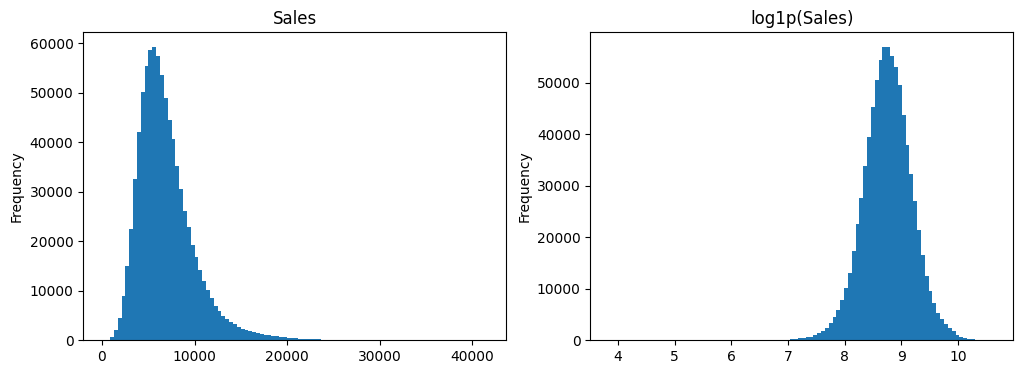

In [39]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
df["Sales"].plot(kind="hist", bins=100, ax=axes[0], title="Sales")
np.log1p(df["Sales"]).plot(kind="hist", bins=100, ax=axes[1], title="log1p(Sales)")
plt.show()

Sales distribution is left skewed. The risk is that few days/stores with extremely high sales (> 15k) \
impact too much the model compared to the vast majority of days/store. \
The distribution after log1p transformation is much more symetric and will therefore be used for modelling.

# Features

In [40]:
# base
df = add_calendar_features(df)   # before the split

features = ["Store", "DayOfWeek", "Promo", "SchoolHoliday", "StateHoliday",
            "Month", "Day", "WeekOfYear", "StoreType", "Assortment", "CompetitionDistance"]

# convert
cat_cols = ["StoreType", "Assortment", "StateHoliday", "Store"]
for c in cat_cols:
    df[c] = df[c].astype("category")


we create calendar features, transform StoreType, Assortment, StateHoliday and Store into categorical variables and select the main features

# Model

In [41]:
# timesplit
cutoff = pd.Timestamp("2015-06-14")
train, validation = split_by_date(df, cutoff)

x_train, y_train = train[features], np.log1p(train["Sales"])
x_valid, y_valid = validation[features], validation["Sales"]

# model
model = lgb.LGBMRegressor(n_estimators=500, learning_rate=0.05)
model.fit(x_train, y_train)

pred = np.expm1(model.predict(x_valid))
raw_gbm_metrics = metrics(y_valid, pred)
raw_gbm_metrics

[LightGBM] [Warning] Categorical features with more bins than the configured maximum bin number found.
[LightGBM] [Warning] For categorical features, max_bin and max_bin_by_feature may be ignored with a large number of categories.
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.018811 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1477
[LightGBM] [Info] Number of data points in the train set: 798454, number of used features: 11
[LightGBM] [Info] Start training from score 8.755916


,RMSPE,RMSE,MAE,WAPE
0,0.136604,1051.033233,727.156732,0.101766


first try with untuned lightgbm gives better RMSPE (0.137) than the baseline (0.143).

In [42]:
# tunig the model
# cross validation: defining the folds by date
cutoffs = [pd.Timestamp("2014-12-01"), pd.Timestamp("2015-03-01"), pd.Timestamp("2015-04-26")]
folds = make_folds(train, cutoffs, horizon_days=48)

for f in folds:
    print(f"Train: {f[0].shape}, Valid: {f[1].shape}")
    print(f"nb of days in common: {len(set(f[0]['Date']).intersection(set(f[1]['Date'])))}")
    print(f"last date in train: {f[0]['Date'].max()}, first date in valid: {f[1]['Date'].min()}")

Train: (624817, 21), Valid: (38853, 21)
nb of days in common: 0
last date in train: 2014-11-30 00:00:00, first date in valid: 2014-12-01 00:00:00
Train: (703838, 21), Valid: (43682, 21)
nb of days in common: 0
last date in train: 2015-02-28 00:00:00, first date in valid: 2015-03-01 00:00:00
Train: (755357, 21), Valid: (41983, 21)
nb of days in common: 0
last date in train: 2015-04-25 00:00:00, first date in valid: 2015-04-26 00:00:00


In [43]:
cv_baseline, summary = cv_score_baseline(folds)
cv_baseline


missing predictions: 0
missing predictions: 0
missing predictions: 0


,RMSPE,RMSE,MAE,WAPE
0,0.241153,2291.726905,1565.584266,0.193751
1,0.151193,1238.447596,789.615288,0.108391
2,0.160438,1241.667539,871.228079,0.115951


The worst fold corresponds to pre-Christmas period to train the model and validate it against the next 48 following days with RMSPE of 0.241 against 0.151 and 0.160 for the other folds.

In [44]:
# average metrics on cv
summary

,mean,std
RMSPE,0.184261,0.049486
RMSE,1590.614013,607.183709
MAE,1075.475878,426.403373
WAPE,0.139364,0.047252


In [45]:
results = []
for num_leaves in [7 , 15, 31, 63]:
    params = dict(num_leaves=num_leaves, n_estimators=5000, learning_rate=0.05)
    per_fold, summary = cv_score(folds, features, params)
    results.append({
        "num_leaves": num_leaves,
        "RMSPE_mean": summary.loc["RMSPE", "mean"],
        "RMSPE_std":  summary.loc["RMSPE", "std"],
        "best_iter_mean": summary.loc["best_iter", "mean"],
    })

pd.DataFrame(results).sort_values("RMSPE_mean")


[LightGBM] [Warning] Categorical features with more bins than the configured maximum bin number found.
[LightGBM] [Warning] For categorical features, max_bin and max_bin_by_feature may be ignored with a large number of categories.
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.010886 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1477
[LightGBM] [Info] Number of data points in the train set: 624817, number of used features: 11
[LightGBM] [Info] Start training from score 8.742371
[LightGBM] [Warning] Categorical features with more bins than the configured maximum bin number found.
[LightGBM] [Warning] For categorical features, max_bin and max_bin_by_feature may be ignored with a large number of categories.
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.017255 seconds.
You can set `force_row_wise

,num_leaves,RMSPE_mean,RMSPE_std,best_iter_mean
2,31,0.151238,0.012495,752.333333
1,15,0.153416,0.012539,676.666667
0,7,0.154333,0.012846,1609.000000
3,63,0.154649,0.015083,482.000000


the tuned lightgbm gives best rmspe of 0.151 with 32 leaves and about m_estimators of 750
by early stopping compared to the baseline with rmspe of 0.184.

# feature engineering

In [46]:
raw = load_data(only_open=False)
holiday_dates = get_holiday_dates(raw)

df = add_features(load_data(), holiday_dates)
train, test = split_by_date(df, cutoff)
folds = make_folds(train, cutoffs)
    

# ablation
configs = {
    "base":                                 features,
    "+ competition":                        features + ["CompetitionMonthsOpen"],
    "+ promo2":                             features + ["Promo2Active"],
    "+ holidays":                           features + ["DaysToHoliday", "DaysSinceHoliday"],
    "+ competition + promo2":               features + ["CompetitionMonthsOpen", "Promo2Active"],
    "+ competition + holidays":             features + ["CompetitionMonthsOpen", "DaysToHoliday", "DaysSinceHoliday"],
    "+ competition + promo2 + holidays":    features + ["CompetitionMonthsOpen", "Promo2Active", "DaysToHoliday", "DaysSinceHoliday"],
}

params = dict(num_leaves=31, n_estimators=5000, learning_rate=0.05)
rows = []
for name, feats in configs.items():
    per_fold, summary = cv_score(folds, feats, params)
    rows.append({
        "config": name,
        "RMSPE_mean": summary.loc["RMSPE", "mean"],
        "RMSPE_std": summary.loc["RMSPE", "std"],
        "fold1 (xmas)": per_fold.loc[0, "RMSPE"],
        "fold2 (easter)": per_fold.loc[1, "RMSPE"],
        "fold3": per_fold.loc[2, "RMSPE"],
        "best_iter_median": per_fold["best_iter"].median(),
    })

ablation = pd.DataFrame(rows).set_index("config")
ablation


[LightGBM] [Warning] Categorical features with more bins than the configured maximum bin number found.
[LightGBM] [Warning] For categorical features, max_bin and max_bin_by_feature may be ignored with a large number of categories.
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.013867 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1477
[LightGBM] [Info] Number of data points in the train set: 624817, number of used features: 11
[LightGBM] [Info] Start training from score 8.742371
[LightGBM] [Warning] Categorical features with more bins than the configured maximum bin number found.
[LightGBM] [Warning] For categorical features, max_bin and max_bin_by_feature may be ignored with a large number of categories.
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.015110 seconds.
You can set `force_row_wise

,RMSPE_mean,RMSPE_std,fold1 (xmas),fold2 (easter),fold3,best_iter_median
config,,,,,,
base,0.151238,0.012495,0.165646,0.144703,0.143366,593.0
+ competition,0.141714,0.014835,0.158777,0.134482,0.131881,728.0
+ promo2,0.151301,0.012880,0.166170,0.143572,0.144160,369.0
+ holidays,0.140171,0.018427,0.161412,0.130635,0.128467,457.0
+ competition + promo2,0.141985,0.012916,0.156898,0.134419,0.134637,634.0
+ competition + holidays,0.127350,0.020237,0.150713,0.116068,0.115268,1352.0
+ competition + promo2 + holidays,0.128063,0.022798,0.154385,0.114589,0.115216,1881.0


The best combination of variables includes the competition and the definition of holidays with a RMSPE of 0.127 compared to the baseline of 0.151. Early stopping shows better n_estimator to 1352 to avoid overfitting.

# final evaluation

In [47]:
# import data
raw = load_data(only_open=False)
holiday_dates = get_holiday_dates(raw)
df = add_features(load_data(), holiday_dates)

# timesplit
cutoff = pd.Timestamp("2015-06-14")
train, validation = split_by_date(df, cutoff)
final_features  = features + ["CompetitionMonthsOpen", "DaysToHoliday", "DaysSinceHoliday"]

x_train, y_train = train[final_features ], np.log1p(train["Sales"])
x_valid, y_valid = validation[final_features ], validation["Sales"]

# model
model = lgb.LGBMRegressor(num_leaves=31, n_estimators=1352, learning_rate=0.05)
model.fit(x_train, y_train)

pred = np.expm1(model.predict(x_valid))
tuned_gbm_metrics = metrics(y_valid, pred)

[LightGBM] [Warning] Categorical features with more bins than the configured maximum bin number found.
[LightGBM] [Warning] For categorical features, max_bin and max_bin_by_feature may be ignored with a large number of categories.
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.012595 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1764
[LightGBM] [Info] Number of data points in the train set: 798454, number of used features: 14
[LightGBM] [Info] Start training from score 8.755916


In [48]:
baseline_store_dow_promo = train.groupby(["Store", "DayOfWeek", "Promo"])["Sales"].mean()
valid = validation.merge(baseline_store_dow_promo, on=["Store", "DayOfWeek", "Promo"], suffixes=("", "_baseline_store_dow_promo"), how="left")

# metrics
baseline_metrics = metrics(valid["Sales"], valid["Sales_baseline_store_dow_promo"])

C:\Users\gdign\AppData\Local\Temp\ipykernel_9616\2031352830.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  baseline_store_dow_promo = train.groupby(["Store", "DayOfWeek", "Promo"])["Sales"].mean()


In [49]:
metrics = pd.concat([baseline_metrics, raw_gbm_metrics, tuned_gbm_metrics], axis=0)
metrics["models"] = ["baseline", "raw_gbm", "tuned_gbm"]
metrics[["models", "RMSPE", "RMSE", "MAE", "WAPE"]]

,models,RMSPE,RMSE,MAE,WAPE
0,baseline,0.142878,1090.145361,737.667038,0.103237
0,raw_gbm,0.136604,1051.033233,727.156732,0.101766
0,tuned_gbm,0.120990,958.793842,653.756773,0.091494


The tuned LightGBM reduces the RMSPE by 15% relative to the baseline (0.121 vs 0.143) when trained on data up to 2015-06-14 \
and validated on the following period. The WAPE is about 9%, meaning the prediction error amounts to roughly 9% of total sales, \
and the MAE is about 654 in sales units per store and day.

# SHAP values

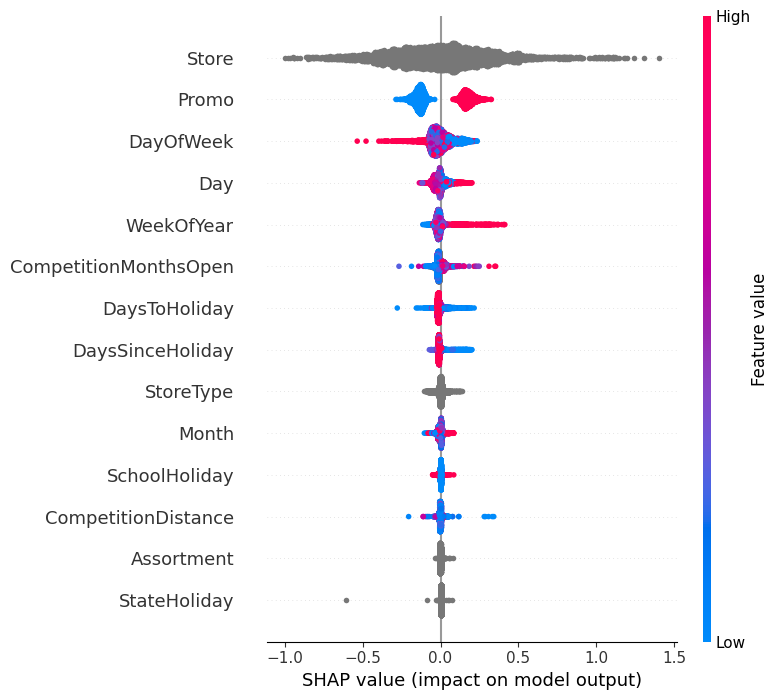

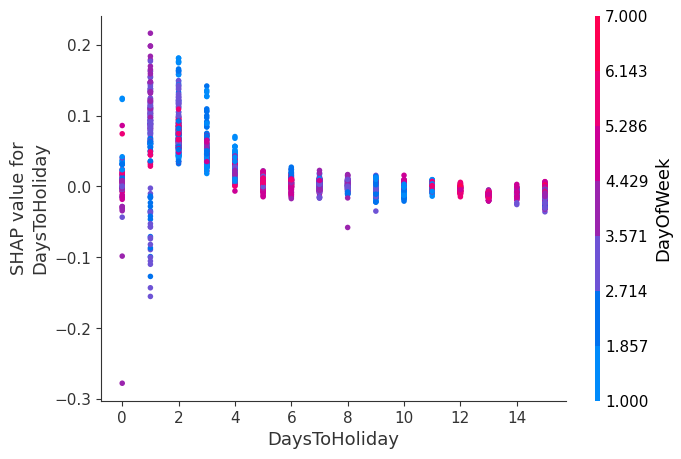

In [56]:
import shap
explainer = shap.TreeExplainer(model)
sample = x_train.sample(5000, random_state=0)      
shap_values = explainer.shap_values(sample)
shap.summary_plot(shap_values, sample)            # global view
shap.dependence_plot("DaysToHoliday", shap_values, sample, interaction_index="DayOfWeek")

SHAP analysis (computed on a sample of the training data) shows that the model learned business-consistent patterns. \
The store identity dominates, followed by promotions (roughly +35% sales on promo days), day of the week (weekends lowest, Monday highest) \
and the year-end season. The holiday features capture a pre-holiday rush: sales rise by about 10-20% in the 1-3 days \
before a holiday and the effect vanishes after roughly 5 days. Note that SHAP explains the model's behaviour, not causal effects.